# ROGII TVT Prediction — Model Training & Validation

## 1. Workflow

1. **Data Preparation** — Check training data quality and generate model features.
2. **Model Training** — Train a regression model to predict TVT changes.
3. **Model Validation** — Evaluate performance using GroupKFold by well.
4. **Model Evaluation** — Compare predictions against baseline methods using RMSE and other metrics.
5. **Final Model Training** — Train the final model using all prepared training examples.
6. **Testing** — Apply the trained model to unseen test wells to generate TVT predictions.

## 2. Objective

Predict True Vertical Thickness (TVT) along the hidden portion of horizontal wellbores after Prediction Start (PS).

The model uses horizontal wellbore measurements and engineered features to estimate TVT.


## 1. Import And Configuration

In [5]:
import json, sys, warnings
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from IPython.display import display

warnings.filterwarnings("ignore", category=RuntimeWarning)
# Works when the notebook is opened in src/ or the project root.
CWD = Path.cwd().resolve()
PROJECT_DIR = CWD.parent if CWD.name == "src" else CWD
SRC_DIR = PROJECT_DIR / "src"
TRAIN_DIR = PROJECT_DIR / "data" / "raw" / "train"
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = PROJECT_DIR / "figures"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
for folder in (RESULTS_DIR, FIGURES_DIR, ARTIFACTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

MAX_WELLS = 0                 # 0 = all wells
MAX_ROWS_PER_WELL = 2000     # development: set None for all hidden rows
N_FOLDS = 5
RANDOM_SEED = 42
assert TRAIN_DIR.is_dir(), f"Training folder not found: {TRAIN_DIR}"
print("Project:", PROJECT_DIR)
print("Train:", TRAIN_DIR)
print("Rows per well:", MAX_ROWS_PER_WELL)

Project: C:\Users\vaish\MSBA265\ROGII-Wellbore-Geology-Prediction
Train: C:\Users\vaish\MSBA265\ROGII-Wellbore-Geology-Prediction\data\raw\train
Rows per well: 2000


## 2. Import Project Feature Engineering

In [6]:
# Import the shared feature-building module.
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))
from Rogii_Features import FEATURES, LOOKBACK_FT, REQUIRED_COLS, build_case
print("Features:", FEATURES)
print("Lookback:", LOOKBACK_FT, "ft")

Features: ['dMD', 'dZ', 'dX', 'dY', 'GR_dev', 'GR_missing', 'slope_x_dMD']
Lookback: 500 ft



## 3. Data preparation check (not model validation)
Check every selected training well using all hidden rows. A few hidden TVT labels may be missing; those rows are excluded from model training, not treated as feature-builder failures.


In [7]:
files = sorted(TRAIN_DIR.rglob("*horizontal_well.csv"))
if MAX_WELLS:
    files = files[:MAX_WELLS]
if not files:
    raise FileNotFoundError("No horizontal training CSV files found")
prep_rows = []
for file_path in files:
    well_id = file_path.name.split("__")[0]
    try:
        df = pd.read_csv(file_path)
        missing = [col for col in list(REQUIRED_COLS) + ["TVT"] if col not in df.columns]
        if missing:
            raise ValueError(f"Missing columns: {missing}")
        X_check, meta_check = build_case(df, max_rows=None)
        if list(X_check.columns) != list(FEATURES):
            raise ValueError("Unexpected feature column order")
        if len(X_check) != len(meta_check):
            raise ValueError("Feature/metadata row count mismatch")
        if not np.isfinite(X_check.to_numpy(dtype=float)).all():
            raise ValueError("Non-finite feature values")
        if "TVT" not in meta_check:
            raise ValueError("TVT missing from metadata")
        valid_targets = int(pd.to_numeric(meta_check["TVT"], errors="coerce").notna().sum())
        if valid_targets == 0:
            raise ValueError("No valid hidden TVT labels")
        prep_rows.append(dict(well_id=well_id, status="PASSED", feature_rows=len(X_check),
                              valid_target_rows=valid_targets, error=""))
    except Exception as exc:
        prep_rows.append(dict(well_id=well_id, status="FAILED", feature_rows=np.nan,
                              valid_target_rows=np.nan, error=str(exc)))
prep_df = pd.DataFrame(prep_rows)
print(prep_df["status"].value_counts().to_string())
display(prep_df.head(10))
failures = prep_df.loc[prep_df["status"] == "FAILED"]
if not failures.empty:
    display(failures)
    raise RuntimeError("Resolve data preparation failures before training")
print("All selected wells passed the data preparation check")

status
PASSED    773


,well_id,status,feature_rows,valid_target_rows,error
0,000d7d20,PASSED,3836,3836,
1,00bbac68,PASSED,6014,6014,
2,00e12e8b,PASSED,4301,4301,
3,015fe0d2,PASSED,4296,4296,
4,01869cd4,PASSED,5557,5557,
5,01982c1d,PASSED,3941,3941,
6,028d7b28,PASSED,6234,6234,
7,02e7fe5a,PASSED,5108,5108,
8,0390d174,PASSED,4411,4411,
9,03a935ae,PASSED,2786,2786,


All selected wells passed the data preparation check


## 4. Metric and model helpers

In [8]:
def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

def metrics(y_true, y_pred):
    return dict(RMSE=rmse(y_true, y_pred),
                MAE=float(mean_absolute_error(y_true, y_pred)),
                R2=float(r2_score(y_true, y_pred)), n_rows=int(len(y_true)))

def make_model():
    return Pipeline([("scaler", StandardScaler()), ("regressor", LinearRegression())])

## 5. Load training examples
Target is TVT change from the last known TVT. X contains only the feature columns from Rogii_Features.py; true hidden TVT is used exclusively as a label and for evaluation.

In [9]:
X_parts, y_parts, meta_parts, skipped = [], [], [], []
for file_path in files:
    well_id = file_path.name.split("__")[0]
    try:
        df = pd.read_csv(file_path)
        X_case, meta_case = build_case(df, max_rows=MAX_ROWS_PER_WELL)
        if not X_case.index.equals(meta_case.index):
            raise ValueError("Feature/metadata index mismatch")
        valid = (pd.to_numeric(meta_case["TVT"], errors="coerce").notna()
                 & pd.to_numeric(meta_case["last_tvt"], errors="coerce").notna())
        X_case = X_case.loc[valid].copy()
        meta_case = meta_case.loc[valid].copy()
        if X_case.empty:
            raise ValueError("No usable target rows")
        y_case = meta_case["TVT"].astype(float) - meta_case["last_tvt"].astype(float)
        meta_case["well_id"] = well_id
        # dMD is a feature; attach it to metadata for baseline and distance analyses.
        meta_case["dMD"] = X_case["dMD"].to_numpy()
        X_parts.append(X_case.reset_index(drop=True))
        y_parts.append(y_case.reset_index(drop=True))
        meta_parts.append(meta_case.reset_index(drop=True))
    except Exception as exc:
        skipped.append(dict(well_id=well_id, error=str(exc)))
if skipped:
    display(pd.DataFrame(skipped))
    raise RuntimeError("Some wells failed training-data loading; fix before proceeding")
X = pd.concat(X_parts, ignore_index=True)
y = pd.concat(y_parts, ignore_index=True)
meta = pd.concat(meta_parts, ignore_index=True)
groups = meta["well_id"].astype(str)
assert list(X.columns) == list(FEATURES)
assert len(X) == len(y) == len(meta)
assert np.isfinite(X.to_numpy(dtype=float)).all() and np.isfinite(y.to_numpy(dtype=float)).all()
print("Feature matrix:", X.shape, "| Wells:", groups.nunique())
display(y.describe())

Feature matrix: (1542405, 7) | Wells: 773


count    1.542405e+06
mean     1.429779e+00
std      1.554432e+01
min     -1.037800e+02
25%     -6.490000e+00
50%      6.700000e-01
75%      9.140000e+00
max      9.891000e+01
dtype: float64

## 6. GroupKFold model validation
Every validation fold contains wells unseen by that fold's trained model. Compare against hold-last-TVT and recent-slope extrapolation.

In [10]:
if groups.nunique() < 2:
    raise ValueError("Need at least two wells for GroupKFold")
n_splits = min(N_FOLDS, groups.nunique())
gkf = GroupKFold(n_splits=n_splits)
oof_model = np.full(len(X), np.nan)
oof_hold = np.zeros(len(X), dtype=float)
oof_linear = X["slope_x_dMD"].to_numpy(dtype=float)
fold_rows = []
for fold, (train_idx, valid_idx) in enumerate(gkf.split(X, y, groups), 1):
    model = make_model()
    model.fit(X.iloc[train_idx], y.iloc[train_idx])
    pred = model.predict(X.iloc[valid_idx])
    oof_model[valid_idx] = pred
    fold_rows.append(dict(fold=fold, train_wells=groups.iloc[train_idx].nunique(),
                          validation_wells=groups.iloc[valid_idx].nunique(),
                          train_rows=len(train_idx), validation_rows=len(valid_idx),
                          hold_RMSE=rmse(y.iloc[valid_idx], oof_hold[valid_idx]),
                          linear_RMSE=rmse(y.iloc[valid_idx], oof_linear[valid_idx]),
                          model_RMSE=rmse(y.iloc[valid_idx], pred)))
assert np.isfinite(oof_model).all()
fold_df = pd.DataFrame(fold_rows)
display(fold_df)
fold_df.to_csv(RESULTS_DIR / "fold_validation_metrics.csv", index=False)

,fold,train_wells,validation_wells,train_rows,validation_rows,hold_RMSE,linear_RMSE,model_RMSE
0,1,619,154,1234405,308000,14.730446,132.915207,14.362817
1,2,619,154,1234405,308000,14.011493,67.065927,13.309420
2,3,618,155,1234109,308296,15.633884,175.323355,14.692532
3,4,618,155,1233642,308763,16.822183,185.235422,16.053124
4,5,618,155,1233059,309346,16.655114,155.592774,15.639655


## 7. Pooled model-validation metrics

In [11]:
overall_metrics = pd.DataFrame([
    dict(model="Hold baseline", **metrics(y, oof_hold)),
    dict(model="Linear extrapolation", **metrics(y, oof_linear)),
    dict(model="Linear regression", **metrics(y, oof_model))
]).set_index("model")
display(overall_metrics)
hold_rmse = overall_metrics.loc["Hold baseline", "RMSE"]
model_rmse = overall_metrics.loc["Linear regression", "RMSE"]
improvement_pct = (hold_rmse - model_rmse) / hold_rmse * 100
print(f"Improvement over hold baseline: {improvement_pct:.2f}%")
print("P1 target: approximately 25% improvement")
overall_metrics.to_csv(RESULTS_DIR / "pooled_validation_metrics.csv")

,RMSE,MAE,R2,n_rows
model,,,,
Hold baseline,15.609936,10.946261,-0.008460,1542405
Linear extrapolation,149.311821,57.176702,-91.266710,1542405
Linear regression,14.844510,10.465576,0.088014,1542405


Improvement over hold baseline: 4.90%
P1 target: approximately 25% improvement


## 8. Per-well performance and out-of-fold predictions

In [12]:
oof_results = meta[["well_id", "MD", "dMD", "last_tvt", "TVT"]].copy()
oof_results["actual_delta"] = y.to_numpy()
oof_results["pred_hold_delta"] = oof_hold
oof_results["pred_linear_delta"] = oof_linear
oof_results["pred_model_delta"] = oof_model
for name in ("hold", "linear", "model"):
    oof_results[f"pred_TVT_{name}"] = oof_results["last_tvt"] + oof_results[f"pred_{name}_delta"]
per_well_rows = []
for well_id, part in oof_results.groupby("well_id"):
    per_well_rows.append(dict(well_id=well_id, n_rows=len(part),
                              hold_RMSE=rmse(part["TVT"], part["pred_TVT_hold"]),
                              linear_RMSE=rmse(part["TVT"], part["pred_TVT_linear"]),
                              model_RMSE=rmse(part["TVT"], part["pred_TVT_model"])))
per_well = pd.DataFrame(per_well_rows)
model_wins = int((per_well["model_RMSE"] < per_well["hold_RMSE"]).sum())
display(per_well.select_dtypes(include="number").describe().T)
print(f"Model beats hold on {model_wins} of {len(per_well)} wells")
per_well.to_csv(RESULTS_DIR / "per_well_validation_metrics.csv", index=False)
oof_results.to_csv(RESULTS_DIR / "oof_predictions.csv", index=False)

,count,mean,std,min,25%,50%,75%,max
n_rows,773.0,1995.349288,71.635788,407.000000,2000.000000,2000.000000,2000.000000,2000.000000
hold_RMSE,773.0,12.811026,8.898464,1.115866,7.099952,10.663293,15.810307,70.630396
linear_RMSE,773.0,66.491839,133.595340,1.111506,16.702272,38.727965,72.121445,1990.422570
model_RMSE,773.0,12.258195,8.352565,1.323646,6.702401,10.003302,14.986643,72.655313


Model beats hold on 464 of 773 wells


## 9. Error by distance from Prediction Start

In [13]:
oof_results["distance_band"] = pd.cut(
    oof_results["dMD"], bins=[-np.inf, 500, 1000, 2000, 5000, np.inf],
    labels=["0–500 ft", "500–1,000 ft", "1,000–2,000 ft", "2,000–5,000 ft", ">5,000 ft"])
distance_rows = []
for band, part in oof_results.groupby("distance_band", observed=False):
    if len(part):
        distance_rows.append(dict(distance_band=str(band), n_rows=len(part),
                                  hold_RMSE_ft=rmse(part["TVT"], part["pred_TVT_hold"]),
                                  linear_RMSE_ft=rmse(part["TVT"], part["pred_TVT_linear"]),
                                  model_RMSE_ft=rmse(part["TVT"], part["pred_TVT_model"])))
distance_metrics = pd.DataFrame(distance_rows)
display(distance_metrics)
distance_metrics.to_csv(RESULTS_DIR / "distance_band_metrics.csv", index=False)

,distance_band,n_rows,hold_RMSE_ft,linear_RMSE_ft,model_RMSE_ft
0,0–500 ft,170010,5.879301,13.056081,5.224368
1,"500–1,000 ft",169131,10.799662,35.383594,9.688462
2,"1,000–2,000 ft",336521,14.330206,70.712500,13.015301
3,"2,000–5,000 ft",761344,17.738107,170.124307,16.828986
4,">5,000 ft",105399,19.861890,314.543916,21.057928


## 10. Diagnostic plots

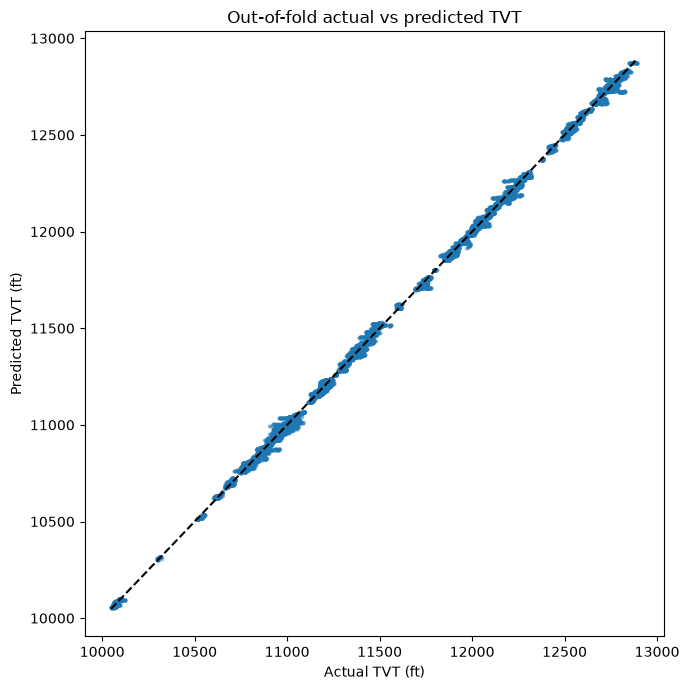

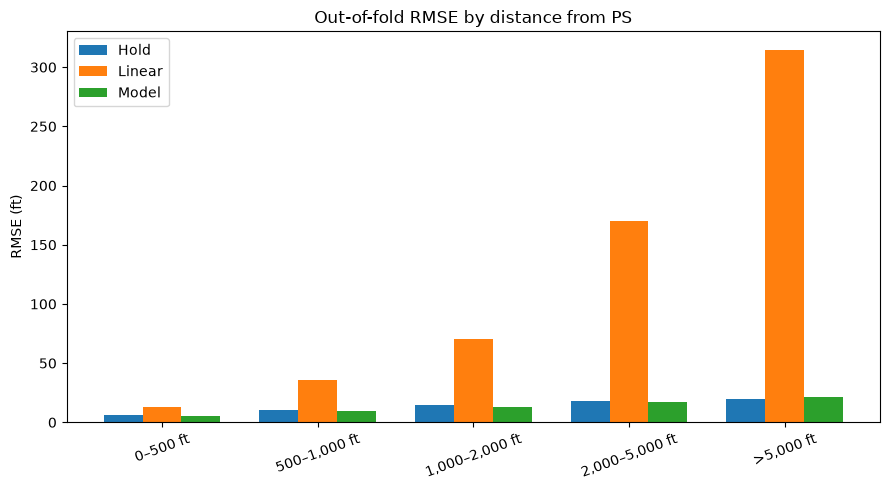

Saved figures to: C:\Users\vaish\MSBA265\ROGII-Wellbore-Geology-Prediction\figures


In [14]:
plot_sample = oof_results.sample(min(50000, len(oof_results)), random_state=RANDOM_SEED)
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(plot_sample["TVT"], plot_sample["pred_TVT_model"], s=4, alpha=0.25)
low = min(plot_sample["TVT"].min(), plot_sample["pred_TVT_model"].min())
high = max(plot_sample["TVT"].max(), plot_sample["pred_TVT_model"].max())
ax.plot([low, high], [low, high], "--", color="black")
ax.set(xlabel="Actual TVT (ft)", ylabel="Predicted TVT (ft)", title="Out-of-fold actual vs predicted TVT")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "oof_actual_vs_predicted.png", dpi=160)
plt.show()
plt.close(fig)

if not distance_metrics.empty:
    fig, ax = plt.subplots(figsize=(9, 5))
    xp = np.arange(len(distance_metrics)); width = 0.25
    for shift, name, col in [(-1, "Hold", "hold_RMSE_ft"), (0, "Linear", "linear_RMSE_ft"), (1, "Model", "model_RMSE_ft")]:
        ax.bar(xp + shift * width, distance_metrics[col], width, label=name)
    ax.set_xticks(xp, distance_metrics["distance_band"], rotation=20)
    ax.set(ylabel="RMSE (ft)", title="Out-of-fold RMSE by distance from PS")
    ax.legend(); fig.tight_layout()
    fig.savefig(FIGURES_DIR / "rmse_by_distance.png", dpi=160)
    plt.show(); plt.close(fig)
print("Saved figures to:", FIGURES_DIR)

## 11. Fit the final core model and save artifacts
This fits on all loaded training examples. With MAX_ROWS_PER_WELL=2000, the final fit is sampled; set it to None and rerun from Section 5 for a full-row fit if memory permits.

In [16]:
final_model = make_model()
final_model.fit(X, y)
model_path = ARTIFACTS_DIR / "rogii_tvt_core_model.joblib"
joblib.dump(final_model, model_path)
model_info = dict(model_type="horizontal_only_core", features=list(FEATURES),
                  lookback_ft=float(LOOKBACK_FT), required_columns=list(REQUIRED_COLS),
                  target="TVT - last_tvt", prediction_reconstruction="TVT_pred = last_tvt + predicted_delta",
                  max_rows_per_well=MAX_ROWS_PER_WELL, trained_wells=int(groups.nunique()),
                  training_rows=int(len(X)), random_seed=RANDOM_SEED)
(ARTIFACTS_DIR / "rogii_tvt_core_model_info.json").write_text(json.dumps(model_info, indent=2))
summary = dict(n_wells=int(groups.nunique()), n_rows=int(len(X)), n_features=len(FEATURES),
               features=list(FEATURES), cv_folds=n_splits, max_rows_per_well=MAX_ROWS_PER_WELL,
               pooled_metrics=overall_metrics.reset_index().to_dict(orient="records"),
               improvement_over_hold_pct=float(improvement_pct), sklearn_version=sklearn.__version__)
(RESULTS_DIR / "training_summary.json").write_text(json.dumps(summary, indent=2))
print("Saved model:", model_path)
print("Saved model information and training summary")

Saved model: C:\Users\vaish\MSBA265\ROGII-Wellbore-Geology-Prediction\artifacts\rogii_tvt_core_model.joblib
Saved model information and training summary


## 12. Final run summary

In [ ]:
print("FINAL RUN SUMMARY")
print("Wells:", groups.nunique(), "| Rows:", len(X), "| Features:", len(FEATURES))
print("GroupKFold folds:", n_splits)
print(f"Hold RMSE: {hold_rmse:.3f} ft")
print(f"Linear RMSE: {overall_metrics.loc['Linear extrapolation', 'RMSE']:.3f} ft")
print(f"Model RMSE: {model_rmse:.3f} ft")
print(f"Improvement over hold: {improvement_pct:.2f}%")
print(f"Wells improved: {model_wins}/{len(per_well)}")

FINAL RUN SUMMARY
Wells: 773 | Rows: 1542405 | Features: 7
GroupKFold folds: 5
Hold RMSE: 15.610 ft
Linear RMSE: 149.312 ft
Model RMSE: 14.845 ft
Improvement over hold: 4.90%
Wells improved: 464/773
Next: separate Kaggle test prediction and typewell-enhanced model
